# 07 — Model Explainability

## Objective
Understand **why** our provisional Random Forest (Balanced) model assigns fraud risk to claims. We will explain model behavior at both global and claim-level, using feature importance, permutation importance, and inspection of the highest-risk claims.

**Business context:** The investigation team has a fixed monthly capacity of 200 claims. We use ranking to prioritize claims—not to automatically reject or accuse customers.

> Explanations describe patterns the model learned from historical data. They are not proof of fraud, causation, or grounds for unfair treatment.

## 1. Setup and load the engineered train/test data
We use the existing stratified split from Task 3 and the same preprocessing/model settings from Task 5.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score, precision_score

warnings.filterwarnings("ignore", category=FutureWarning)

search_start = Path.cwd().resolve()
project_root = None
for candidate in [search_start, *search_start.parents]:
    if (candidate / "data" / "processed" / "X_train.csv").exists():
        project_root = candidate
        break
if project_root is None:
    raise FileNotFoundError("Could not find data/processed/X_train.csv from current directory")

DATA_DIR = project_root / "data" / "processed"
REPORTS_DIR = project_root / "reports"
REPORTS_DIR.mkdir(exist_ok=True)
print("Project root:", project_root)

Project root: C:\Users\rudra\OneDrive\Documents\insurance-claim-fraud-detection\insurance-claim-fraud-detection


In [2]:
X_train = pd.read_csv(DATA_DIR / "X_train.csv")
X_test = pd.read_csv(DATA_DIR / "X_test.csv")
y_train = pd.read_csv(DATA_DIR / "y_train.csv").squeeze()
y_test = pd.read_csv(DATA_DIR / "y_test.csv").squeeze()

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Train fraud rate:", y_train.mean().round(4))
print("Test fraud rate:", y_test.mean().round(4))

Train: (12336, 42) Test: (3084, 42)
Train fraud rate: 0.0598
Test fraud rate: 0.06


## 2. Recreate the Task 5 Random Forest pipeline
We keep the same settings: 100 trees, `class_weight="balanced_subsample"`, `min_samples_leaf=2`, and `random_state=42`. Numeric variables are median-imputed and scaled; categorical variables are mode-imputed and one-hot encoded. Preprocessing is fit on training data only.

In [3]:
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

def make_preprocessor():
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])
    return ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ])

rf_pipeline = Pipeline([
    ("preprocessing", make_preprocessor()),
    ("model", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced_subsample",
        min_samples_leaf=2,
        n_jobs=1,
        random_state=42
    ))
])

rf_pipeline.fit(X_train, y_train)
test_prob = rf_pipeline.predict_proba(X_test)[:, 1]
print("Pipeline trained. Test Average Precision:", round(average_precision_score(y_test, test_prob), 4))

Pipeline trained. Test Average Precision: 0.2317


## 3. Global feature importance — Random Forest impurity importance
This ranking shows which encoded features contributed most to reducing impurity across the trees. Categorical variables appear as individual one-hot levels.

**Caution:** impurity-based importance can favor variables with many possible values and may spread importance across encoded categories. Treat it as a first look, not a definitive ranking of business causes.

In [4]:
rf = rf_pipeline.named_steps["model"]
preprocessor = rf_pipeline.named_steps["preprocessing"]
encoded_feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Encoded_Feature": encoded_feature_names,
    "Importance": rf.feature_importances_
}).sort_values("Importance", ascending=False)

importance_df.head(20)

,Encoded_Feature,Importance
82,categorical__Fault_Policy Holder,0.073862
83,categorical__Fault_Third Party,0.066675
154,categorical__BasePolicy_Liability,0.048988
2,numeric__Age,0.041080
86,categorical__PolicyType_Sedan - Liability,0.027418
94,categorical__VehicleCategory_Sport,0.026826
1,numeric__WeekOfMonthClaimed,0.022107
0,numeric__WeekOfMonth,0.021620
5,numeric__Year,0.021198
93,categorical__VehicleCategory_Sedan,0.020604


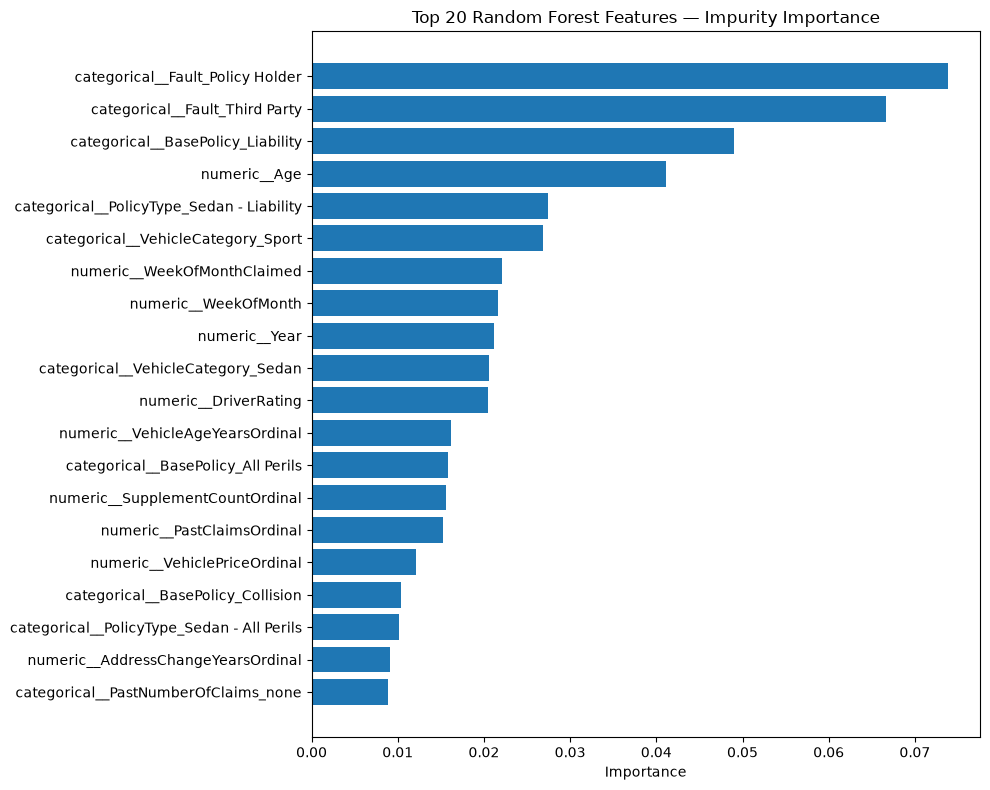

In [5]:
top_imp = importance_df.head(20).sort_values("Importance")
plt.figure(figsize=(10, 8))
plt.barh(top_imp["Encoded_Feature"], top_imp["Importance"])
plt.title("Top 20 Random Forest Features — Impurity Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## 4. Aggregate one-hot importance back to original variables
One original categorical variable can produce many encoded columns. We aggregate their importance to provide a variable-level view. This is still impurity-based importance and retains its limitations.

In [6]:
feature_groups = []
for original_feature in numeric_features:
    matching = [f for f in encoded_feature_names if f.startswith(f"numeric__{original_feature}")]
    feature_groups.append((original_feature, matching))
for original_feature in categorical_features:
    prefix = f"categorical__{original_feature}_"
    matching = [f for f in encoded_feature_names if f.startswith(prefix)]
    feature_groups.append((original_feature, matching))

aggregated = []
for original_feature, encoded_features in feature_groups:
    total = importance_df.loc[importance_df["Encoded_Feature"].isin(encoded_features), "Importance"].sum()
    aggregated.append({"Original_Feature": original_feature, "Aggregated_Importance": total})
aggregate_importance = pd.DataFrame(aggregated).sort_values("Aggregated_Importance", ascending=False)
aggregate_importance.head(20)

,Original_Feature,Aggregated_Importance
25,Fault,0.140537
40,BasePolicy,0.075250
17,Month,0.055047
22,MonthClaimed,0.051968
26,PolicyType,0.051896
27,VehicleCategory,0.050157
0,WeekOfMonth,0.043728
18,DayOfWeek,0.042719
19,Make,0.041364
2,Age,0.041080


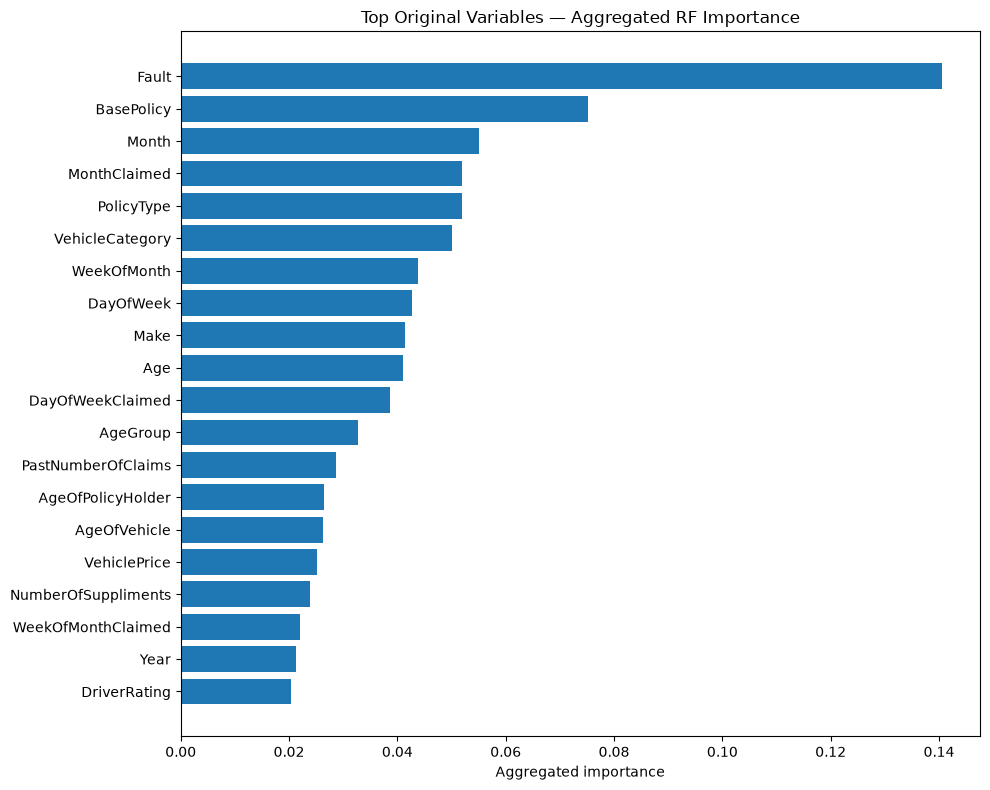

In [7]:
top_agg = aggregate_importance.head(20).sort_values("Aggregated_Importance")
plt.figure(figsize=(10, 8))
plt.barh(top_agg["Original_Feature"], top_agg["Aggregated_Importance"])
plt.title("Top Original Variables — Aggregated RF Importance")
plt.xlabel("Aggregated importance")
plt.tight_layout()
plt.show()

## 5. Permutation importance on held-out test data
Permutation importance measures the decrease in a chosen performance metric when the values of one original feature are shuffled. We use **Average Precision (PR-AUC)** because fraud is a minority class.

We also calculate a custom capacity-based scorer, **Precision@K**, where K is scaled to the test-set size (approximately 40 claims for our assumed capacity of 200/month). These scores are diagnostic on the test set; avoid repeatedly using test results to tune the model.

In [8]:
capacity_monthly = 200
test_fraction = len(y_test) / (len(y_train) + len(y_test))
k_test = max(1, int(round(capacity_monthly * test_fraction)))

def precision_at_k_scorer(estimator, X, y):
    probabilities = estimator.predict_proba(X)[:, 1]
    k = max(1, int(round(capacity_monthly * len(y) / (len(y_train) + len(y_test)))))
    top_indices = np.argsort(probabilities)[::-1][:k]
    return float(np.asarray(y)[top_indices].mean())

perm_ap = permutation_importance(
    rf_pipeline, X_test, y_test,
    scoring="average_precision",
    n_repeats=5, random_state=42, n_jobs=1
)
perm_pk = permutation_importance(
    rf_pipeline, X_test, y_test,
    scoring=precision_at_k_scorer,
    n_repeats=5, random_state=42, n_jobs=1
)

permutation_df = pd.DataFrame({
    "Feature": X_test.columns,
    "AP_Importance_Mean": perm_ap.importances_mean,
    "AP_Importance_Std": perm_ap.importances_std,
    "Precision_at_K_Importance_Mean": perm_pk.importances_mean,
    "Precision_at_K_Importance_Std": perm_pk.importances_std
}).sort_values("AP_Importance_Mean", ascending=False)
permutation_df.head(20)

,Feature,AP_Importance_Mean,AP_Importance_Std,Precision_at_K_Importance_Mean,Precision_at_K_Importance_Std
11,Fault,0.104427,0.012041,1.900000e-01,0.025495
29,BasePolicy,0.040831,0.014980,4.500000e-02,0.043012
12,PolicyType,0.025800,0.009478,7.500000e-02,0.063246
28,Year,0.024650,0.008801,4.500000e-02,0.018708
26,AddressChange_Claim,0.020646,0.003078,4.500000e-02,0.010000
13,VehicleCategory,0.015163,0.008742,5.500000e-02,0.029155
39,AddressChangeYearsOrdinal,0.011080,0.002030,1.110223e-17,0.015811
15,Deductible,0.010168,0.002080,5.000000e-03,0.010000
19,PastNumberOfClaims,0.009632,0.003142,6.500000e-02,0.033912
14,VehiclePrice,0.008721,0.005218,9.000000e-02,0.037417


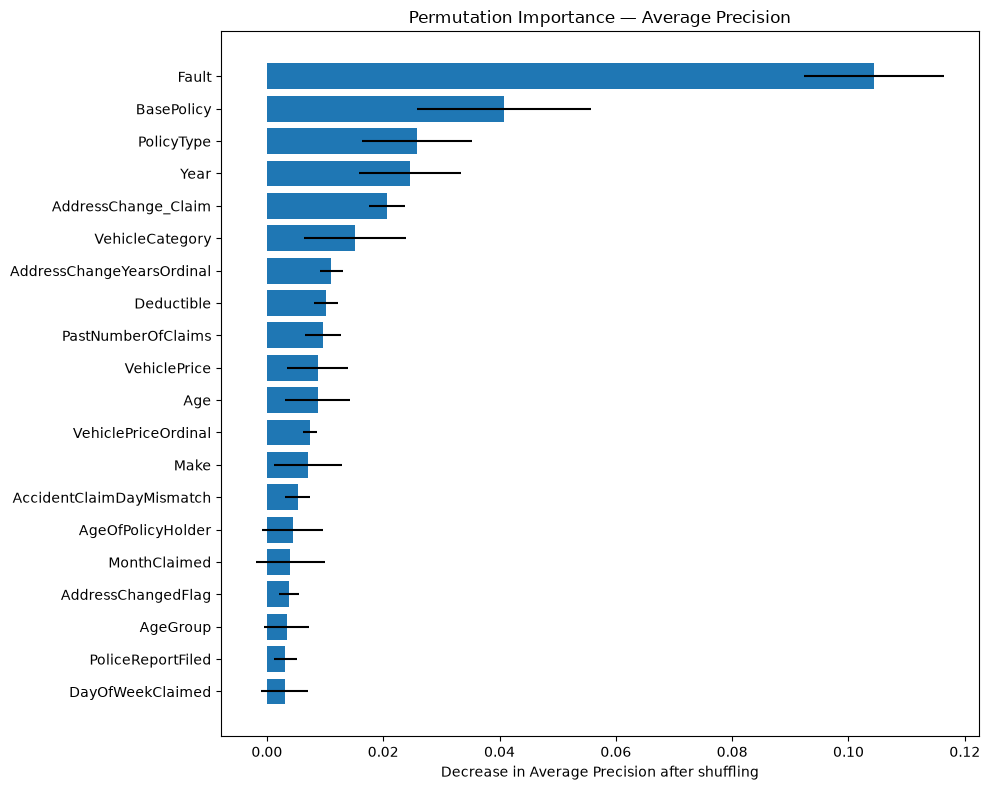

In [9]:
top_perm = permutation_df.head(20).sort_values("AP_Importance_Mean")
plt.figure(figsize=(10, 8))
plt.barh(top_perm["Feature"], top_perm["AP_Importance_Mean"], xerr=top_perm["AP_Importance_Std"])
plt.title("Permutation Importance — Average Precision")
plt.xlabel("Decrease in Average Precision after shuffling")
plt.tight_layout()
plt.show()

## 6. Capacity-based risk ranking — inspect the Top-K claims
We select the top K test claims by model probability. The goal here is to inspect what patterns/features are present in the highest-risk queue—not to treat these patterns as evidence of wrongdoing.

In [10]:
risk_ranked_test = X_test.copy().reset_index(drop=True)
risk_ranked_test["Actual_Fraud"] = y_test.reset_index(drop=True)
risk_ranked_test["Predicted_Fraud_Probability"] = test_prob
risk_ranked_test["Risk_Rank"] = risk_ranked_test["Predicted_Fraud_Probability"].rank(method="first", ascending=False).astype(int)

top_k_claims = risk_ranked_test.sort_values("Predicted_Fraud_Probability", ascending=False).head(k_test)
print(f"K for test set: {k_test}")
print("Fraud captured in Top-K:", int(top_k_claims["Actual_Fraud"].sum()))
print("Precision@K:", round(top_k_claims["Actual_Fraud"].mean(), 4))
top_k_claims.head(10)

K for test set: 40
Fraud captured in Top-K: 16
Precision@K: 0.4


,Month,WeekOfMonth,DayOfWeek,Make,AccidentArea,DayOfWeekClaimed,MonthClaimed,WeekOfMonthClaimed,Sex,MaritalStatus,...,PastClaimsOrdinal,SupplementCountOrdinal,DaysPolicyAccidentOrdinal,DaysPolicyClaimOrdinal,AddressChangeYearsOrdinal,VehiclePriceOrdinal,NumberOfCarsOrdinal,Actual_Fraud,Predicted_Fraud_Probability,Risk_Rank
1628,May,1,Sunday,Honda,Urban,Tuesday,May,3,Male,Single,...,0,0.0,31.0,31.0,NaN,6,1.0,1,0.801150,1
1330,Dec,3,Friday,Pontiac,Urban,Tuesday,Jan,3,Male,Married,...,3,0.0,0.0,31.0,2.5,1,1.0,1,0.634769,2
2551,Aug,1,Tuesday,Accura,Urban,Friday,Aug,2,Male,Single,...,0,0.0,31.0,31.0,NaN,6,1.0,0,0.621420,3
1203,Nov,1,Saturday,Ford,Urban,Wednesday,Nov,2,Male,Married,...,3,1.5,31.0,31.0,2.5,4,1.0,1,0.589039,4
1078,Sep,1,Monday,Honda,Rural,Tuesday,Sep,1,Male,Single,...,0,0.0,31.0,31.0,NaN,6,1.0,1,0.573571,5
2950,Mar,1,Sunday,Honda,Urban,Wednesday,Mar,3,Male,Single,...,0,0.0,31.0,31.0,NaN,6,1.0,1,0.540222,6
1676,Jun,3,Thursday,Chevrolet,Rural,Thursday,Jun,3,Male,Married,...,0,1.5,31.0,31.0,2.5,6,1.0,1,0.531197,7
1221,Mar,5,Monday,Honda,Urban,Friday,May,1,Male,Single,...,0,0.0,31.0,31.0,NaN,6,1.0,0,0.530369,8
978,Jan,2,Tuesday,Honda,Urban,Friday,Jan,4,Male,Single,...,0,0.0,31.0,31.0,NaN,6,1.0,1,0.512136,9
2203,Dec,5,Wednesday,Honda,Urban,Wednesday,Jan,3,Male,Single,...,0,0.0,31.0,31.0,NaN,6,1.0,0,0.503214,10


## 7. Compare feature patterns in Top-K vs all test claims
This descriptive comparison may help generate investigation hypotheses. Differences are associations in this dataset, not causal relationships or proof of fraud. For categorical variables, we show the most common values in the Top-K queue.

In [11]:
topk_feature_summary = []
for col in X_test.columns:
    if X_test[col].dtype == "object" or X_test[col].nunique(dropna=True) <= 10:
        overall = X_test[col].value_counts(normalize=True, dropna=False).head(5)
        topk = top_k_claims[col].value_counts(normalize=True, dropna=False).head(5)
        topk_feature_summary.append({
            "Feature": col,
            "Overall_Top_Values": overall.to_dict(),
            "TopK_Top_Values": topk.to_dict()
        })

pattern_summary = pd.DataFrame(topk_feature_summary)
pattern_summary.head(20)

,Feature,Overall_Top_Values,TopK_Top_Values
0,WeekOfMonth,"{2: 0.22957198443579765, 3: 0.2285992217898832...","{1: 0.325, 2: 0.2, 4: 0.2, 3: 0.175, 5: 0.1}"
1,DayOfWeek,"{'Friday': 0.1618028534370947, 'Monday': 0.160...","{'Monday': 0.25, 'Sunday': 0.2, 'Tuesday': 0.1..."
2,AccidentArea,"{'Urban': 0.9072632944228275, 'Rural': 0.09273...","{'Urban': 0.875, 'Rural': 0.125}"
3,DayOfWeekClaimed,"{'Monday': 0.23865110246433205, 'Tuesday': 0.2...","{'Tuesday': 0.325, 'Wednesday': 0.2, 'Thursday..."
4,WeekOfMonthClaimed,"{2: 0.23929961089494164, 1: 0.2389753566796368...","{3: 0.35, 2: 0.275, 1: 0.2, 5: 0.1, 4: 0.075}"
5,Sex,"{'Male': 0.8375486381322957, 'Female': 0.16245...","{'Male': 0.975, 'Female': 0.025}"
6,MaritalStatus,"{'Married': 0.7013618677042801, 'Single': 0.29...","{'Single': 0.5, 'Married': 0.5}"
7,Fault,"{'Policy Holder': 0.7315175097276264, 'Third P...","{'Policy Holder': 0.925, 'Third Party': 0.075}"
8,PolicyType,"{'Sedan - Collision': 0.3544098573281453, 'Sed...","{'Sedan - All Perils': 0.675, 'Sport - Collisi..."
9,VehicleCategory,"{'Sedan': 0.6303501945525292, 'Sport': 0.34435...","{'Sedan': 0.725, 'Sport': 0.175, 'Utility': 0.1}"


## 8. Explain one high-risk claim (case-level inspection)
We inspect one claim selected from the Top-K queue. The table shows the claim’s model score and feature values. It is a transparent profile of the claim, but it does **not** tell us which individual feature caused the probability. For a true contribution-based local explanation, use the optional SHAP section below.

In [12]:
# Choose the highest-risk claim in the Top-K queue for inspection
example_claim = top_k_claims.iloc[0]
example_claim_id = example_claim.name
example_probability = example_claim["Predicted_Fraud_Probability"]
example_actual = example_claim["Actual_Fraud"]

print("Risk rank:", int(example_claim["Risk_Rank"]))
print("Predicted fraud probability:", round(float(example_probability), 4))
print("Actual label (for retrospective learning only):", int(example_actual))

claim_profile = example_claim.drop(labels=["Actual_Fraud", "Predicted_Fraud_Probability", "Risk_Rank"]).to_frame("Value")
claim_profile

Risk rank: 1
Predicted fraud probability: 0.8011
Actual label (for retrospective learning only): 1


,Value
Month,May
WeekOfMonth,1
DayOfWeek,Sunday
Make,Honda
AccidentArea,Urban
DayOfWeekClaimed,Tuesday
MonthClaimed,May
WeekOfMonthClaimed,3
Sex,Male
MaritalStatus,Single


## 9. Optional: SHAP local/global explanations
SHAP is optional because it may not be installed in every environment. If available, we use TreeExplainer on the fitted Random Forest with the transformed feature matrix. SHAP values help describe contributions to model output; interpret them carefully, especially with correlated features and encoded categories.

In [13]:
try:
    import shap
    transformed_test = preprocessor.transform(X_test)
    # Use a manageable sample for computation and plots.
    sample_size = min(300, transformed_test.shape[0])
    sample_idx = np.random.RandomState(42).choice(transformed_test.shape[0], sample_size, replace=False)
    shap_explainer = shap.TreeExplainer(rf)
    shap_values = shap_explainer.shap_values(transformed_test[sample_idx])
    print("SHAP installed and values calculated. Shape:", np.asarray(shap_values).shape)
except Exception as e:
    print("SHAP section skipped (optional dependency or compatibility issue):", repr(e))
    print("If desired, install SHAP separately and rerun this section.")

SHAP section skipped (optional dependency or compatibility issue): UFuncTypeError(<ufunc 'isnan'>, 'same_kind', dtype('O'), dtype('bool'), 0)
If desired, install SHAP separately and rerun this section.


## 10. Save explainability artifacts
Save the importance rankings and Top-K claim list for portfolio documentation. The Top-K file contains test rows and labels, so keep it as an educational artifact and avoid presenting individual records as real investigations.

In [14]:
importance_path = REPORTS_DIR / "rf_encoded_feature_importance.csv"
aggregate_path = REPORTS_DIR / "rf_aggregated_feature_importance.csv"
permutation_path = REPORTS_DIR / "rf_permutation_importance.csv"
topk_path = REPORTS_DIR / "rf_top_k_test_claims_explainability.csv"

importance_df.to_csv(importance_path, index=False)
aggregate_importance.to_csv(aggregate_path, index=False)
permutation_df.to_csv(permutation_path, index=False)
top_k_claims.to_csv(topk_path, index=False)
print("Saved artifacts:")
for path in [importance_path, aggregate_path, permutation_path, topk_path]:
    print(path)

Saved artifacts:
C:\Users\rudra\OneDrive\Documents\insurance-claim-fraud-detection\insurance-claim-fraud-detection\reports\rf_encoded_feature_importance.csv
C:\Users\rudra\OneDrive\Documents\insurance-claim-fraud-detection\insurance-claim-fraud-detection\reports\rf_aggregated_feature_importance.csv
C:\Users\rudra\OneDrive\Documents\insurance-claim-fraud-detection\insurance-claim-fraud-detection\reports\rf_permutation_importance.csv
C:\Users\rudra\OneDrive\Documents\insurance-claim-fraud-detection\insurance-claim-fraud-detection\reports\rf_top_k_test_claims_explainability.csv


## 11. Findings to document after running

The Random Forest (Balanced) model currently provides the strongest performance for our capacity-based fraud detection objective, achieving 40% Precision@40 and capturing 16 fraud cases within the Top-40 test claims.

Model explainability adds an important layer of transparency by helping us understand the model's behavior, investigate high-risk claim patterns, and communicate risk signals to the investigation team.

However, explainability must be interpreted carefully. Feature importance indicates predictive associations learned by the model—not causal relationships or proof of fraudulent activity.

Our proposed system should therefore function as a risk-prioritization and investigation-support system with human oversight, rather than an automated fraud-decision system.